# Uber Supply-Demand Gap Analysis
### An Exploratory Data Analysis Case Study

**Author:** Karunesh  
**Tools Used:** Python (Pandas, Matplotlib, Seaborn), SQLite / SQL  
**Dataset:** 6,745 Uber ride requests (July 11–15, 2016)

---

## 1. Project Overview

I built this project to understand why so many Uber ride requests were being cancelled or left without a car, when these issues happen most often, and how ride availability compares between City and Airport pickups.

### Questions I Wanted to Answer:
1. What percentage of total ride requests were completed, cancelled, or had no cars available?
2. At what hours of the day do most unfulfilled requests occur?
3. How do cancellations and car shortages compare between the City and the Airport?
4. How do morning rush patterns differ from evening rush patterns?
5. What operational adjustments could Uber test to reduce these gaps?


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Data Loading & Initial Inspection

First, I load the dataset and check its dimensions, column types, and first few rows.


In [2]:
# Load the dataset
candidates = [
    os.path.join('..', 'data', 'raw', 'uber_request_data.csv'),
    os.path.join('data', 'raw', 'uber_request_data.csv'),
    os.path.join('..', 'data', 'uber_cleaned_data.csv'),
    os.path.join('data', 'uber_cleaned_data.csv')
]
data_path = None
for p in candidates:
    if os.path.exists(p):
        data_path = p
        break

df = pd.read_csv(data_path)
print(f"Loaded dataset from: {data_path}")
print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Loaded dataset from: ..\data\raw\uber_request_data.csv
Dataset shape: 6745 rows, 6 columns


,Request id,Pickup point,Driver id,Status,Request timestamp,Drop timestamp
0,619,Airport,1.0,Trip Completed,11/7/16 11:51,11/7/16 13:00
1,867,Airport,1.0,Trip Completed,11/7/16 17:57,11/7/16 18:47
2,1807,City,1.0,Trip Completed,12/7/16 9:17,12/7/16 9:58
3,2532,Airport,1.0,Trip Completed,12/7/16 21:08,12/7/16 22:03
4,3112,City,1.0,Trip Completed,13-07-2016 08:33:16,13-07-2016 09:25:47


In [3]:
# Check column types and missing values
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6745 entries, 0 to 6744
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Request id         6745 non-null   int64  
 1   Pickup point       6745 non-null   object 
 2   Driver id          4095 non-null   float64
 3   Status             6745 non-null   object 
 4   Request timestamp  6745 non-null   object 
 5   Drop timestamp     2831 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 316.3+ KB

Missing values per column:
Request id              0
Pickup point            0
Driver id            2650
Status                  0
Request timestamp       0
Drop timestamp       3914
dtype: int64


### Missing Values and Request Status

First, I checked the dataset for missing values. I noticed that some driver IDs and drop timestamps were missing, so I compared them with the request status:
- `Driver id` is missing in **2,650 rows** (39.29%).
- `Drop timestamp` is missing in **3,914 rows** (58.03%).

When comparing missing values against the `Status` column, the pattern makes operational sense:
- **Trip Completed (2,831 rows):** Both Driver ID and Drop timestamp are present.
- **Cancelled (1,264 rows):** Driver ID is present because a driver accepted the trip, but Drop timestamp is empty because the ride was cancelled before completion.
- **No Cars Available (2,650 rows):** Both Driver ID and Drop timestamp are empty because no driver was ever assigned.

Here is a quick check to verify this relationship:


In [4]:
# Verify missing values across trip statuses
missing_analysis = df.groupby('Status').agg(
    total_trips=('Request id', 'count'),
    missing_driver_id=('Driver id', lambda x: x.isnull().sum()),
    missing_drop_timestamp=('Drop timestamp', lambda x: x.isnull().sum())
).reset_index()

missing_analysis['pct_missing_drop'] = (missing_analysis['missing_drop_timestamp'] / missing_analysis['total_trips']) * 100
missing_analysis


,Status,total_trips,missing_driver_id,missing_drop_timestamp,pct_missing_drop
0,Cancelled,1264,0,1264,100.0
1,No Cars Available,2650,2650,2650,100.0
2,Trip Completed,2831,0,0,0.0


## 3. Data Cleaning and Feature Extraction

Next, I cleaned the dataset and created a few helper columns:
1. Standardized column names to lowercase snake_case.
2. Parsed request and drop timestamps into datetime format.
3. Extracted request hour, date, and day of week.
4. Grouped the hours into 5 practical time slots (Early Morning, Morning Rush, Midday, Evening Rush, Late Night).
5. Added binary indicator columns (`is_completed`, `is_cancelled`, `is_no_cars`, `is_unfulfilled`) for easier aggregation.


In [5]:
# Standardize column names
df = df.rename(columns={
    'Request id': 'request_id',
    'Pickup point': 'pickup_point',
    'Driver id': 'driver_id',
    'Status': 'status',
    'Request timestamp': 'request_timestamp',
    'Drop timestamp': 'drop_timestamp'
})

# Convert timestamps to datetime
df['request_timestamp'] = pd.to_datetime(df['request_timestamp'], dayfirst=True, format='mixed')
df['drop_timestamp'] = pd.to_datetime(df['drop_timestamp'], dayfirst=True, format='mixed')

# Extract time features
df['request_date'] = df['request_timestamp'].dt.date
df['request_hour'] = df['request_timestamp'].dt.hour
df['day_name'] = df['request_timestamp'].dt.day_name()

# Categorize into 5 time slots
def categorize_time(hour):
    if 0 <= hour < 5:
        return 'Early Morning (12 AM - 5 AM)'
    elif 5 <= hour < 10:
        return 'Morning Rush (5 AM - 10 AM)'
    elif 10 <= hour < 17:
        return 'Midday (10 AM - 5 PM)'
    elif 17 <= hour < 22:
        return 'Evening Rush (5 PM - 10 PM)'
    else:
        return 'Late Night (10 PM - 12 AM)'

df['time_slot'] = df['request_hour'].apply(categorize_time)

# Add binary flags
df['is_completed'] = (df['status'] == 'Trip Completed').astype(int)
df['is_cancelled'] = (df['status'] == 'Cancelled').astype(int)
df['is_no_cars'] = (df['status'] == 'No Cars Available').astype(int)
df['is_unfulfilled'] = (df['status'] != 'Trip Completed').astype(int)

print(f"Data cleaning complete. Date range: {df['request_date'].min()} to {df['request_date'].max()}")
print(f"Days of the week present: {df['day_name'].unique().tolist()}")


Data cleaning complete. Date range: 2016-07-11 to 2016-07-15
Days of the week present: ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']


## 4. Overall Request Performance

Here, I look at the overall breakdown of ride statuses across all 6,745 requests.


In [6]:
status_summary = df['status'].value_counts().reset_index()
status_summary.columns = ['Status', 'Total Requests']
status_summary['Percentage (%)'] = (status_summary['Total Requests'] / len(df) * 100).round(2)

print("=== OVERALL STATUS SUMMARY ===")
print(status_summary.to_string(index=False))

total_requests = len(df)
completed = (df['status'] == 'Trip Completed').sum()
unfulfilled = total_requests - completed
no_cars = (df['status'] == 'No Cars Available').sum()
cancelled = (df['status'] == 'Cancelled').sum()

print(f"\nKey Baseline Counts:")
print(f"- Total Requests: {total_requests:,}")
print(f"- Completed Trips: {completed:,} ({completed/total_requests*100:.2f}%)")
print(f"- Unfulfilled Requests: {unfulfilled:,} ({unfulfilled/total_requests*100:.2f}%)")
print(f"- No Cars Available: {no_cars:,} ({no_cars/total_requests*100:.2f}%)")
print(f"- Driver Cancellations: {cancelled:,} ({cancelled/total_requests*100:.2f}%)")


=== OVERALL STATUS SUMMARY ===
           Status  Total Requests  Percentage (%)
   Trip Completed            2831           41.97
No Cars Available            2650           39.29
        Cancelled            1264           18.74

Key Baseline Counts:
- Total Requests: 6,745
- Completed Trips: 2,831 (41.97%)
- Unfulfilled Requests: 3,914 (58.03%)
- No Cars Available: 2,650 (39.29%)
- Driver Cancellations: 1,264 (18.74%)


C:\Users\ms761\AppData\Local\Temp\ipykernel_32608\358458470.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=status_summary, x='Status', y='Total Requests', palette=colors, ax=ax2)


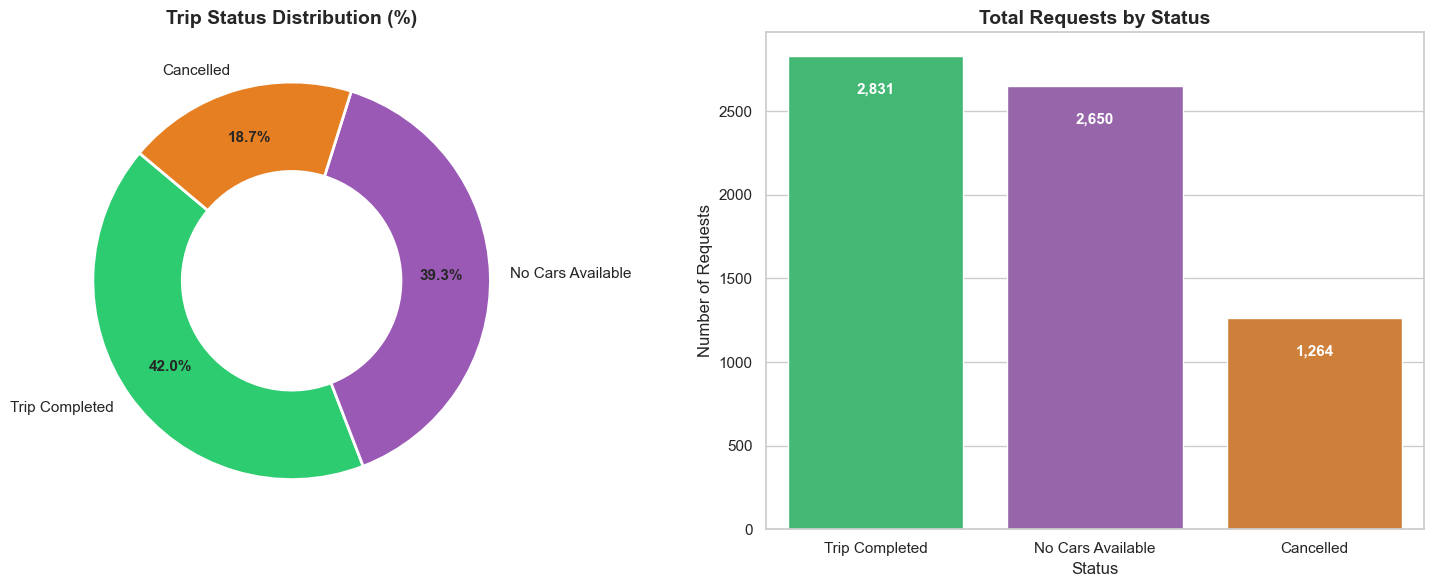

In [7]:
# Visualization 1: Trip status breakdown
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

colors = ['#2ecc71', '#9b59b6', '#e67e22']
wedges, texts, autotexts = ax1.pie(
    status_summary['Total Requests'],
    labels=status_summary['Status'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='w', linewidth=2)
)
plt.setp(autotexts, size=11, weight="bold")
ax1.set_title("Trip Status Distribution (%)", fontsize=14, weight='bold')

sns.barplot(data=status_summary, x='Status', y='Total Requests', palette=colors, ax=ax2)
ax2.set_title("Total Requests by Status", fontsize=14, weight='bold')
ax2.set_ylabel("Number of Requests")
for p in ax2.patches:
    ax2.annotate(f"{int(p.get_height()):,}", 
                 (p.get_x() + p.get_width() / 2., p.get_height() - 200),
                 ha='center', va='center', fontsize=11, color='white', weight='bold')

plt.tight_layout()
plt.show()


## 5. Demand and Supply Patterns by Hour

Next, I looked at which hours had the most unsuccessful requests, and how completed trips compare with unfulfilled demand across the 24 hours of the day:
- Which hours receive the most requests?
- Which hours have the highest volume of unfulfilled rides?
- How do cancellation rates and car shortages change throughout the day?


In [8]:
hourly_df = df.groupby('request_hour').agg(
    total_demand=('request_id', 'count'),
    completed_supply=('is_completed', 'sum'),
    cancellations=('is_cancelled', 'sum'),
    no_cars=('is_no_cars', 'sum'),
    unfulfilled_gap=('is_unfulfilled', 'sum')
).reset_index()

hourly_df['unfulfilled_rate_pct'] = (hourly_df['unfulfilled_gap'] / hourly_df['total_demand'] * 100).round(2)
hourly_df['cancellation_rate_pct'] = (hourly_df['cancellations'] / hourly_df['total_demand'] * 100).round(2)
hourly_df['no_cars_rate_pct'] = (hourly_df['no_cars'] / hourly_df['total_demand'] * 100).round(2)

print("Top 5 Hours by Total Requests:")
print(hourly_df.sort_values(by='total_demand', ascending=False)[['request_hour', 'total_demand', 'completed_supply', 'unfulfilled_gap', 'unfulfilled_rate_pct']].head(5).to_string(index=False))

print("\nTop 5 Hours by Unfulfilled Count:")
print(hourly_df.sort_values(by='unfulfilled_gap', ascending=False)[['request_hour', 'unfulfilled_gap', 'total_demand', 'unfulfilled_rate_pct', 'cancellations', 'no_cars']].head(5).to_string(index=False))


Top 5 Hours by Total Requests:
 request_hour  total_demand  completed_supply  unfulfilled_gap  unfulfilled_rate_pct
           18           510               164              346                 67.84
           20           492               161              331                 67.28
           19           473               166              307                 64.90
           21           449               142              307                 68.37
            5           445               185              260                 58.43

Top 5 Hours by Unfulfilled Count:
 request_hour  unfulfilled_gap  total_demand  unfulfilled_rate_pct  cancellations  no_cars
           18              346           510                 67.84             24      322
           20              331           492                 67.28             41      290
           21              307           449                 68.37             42      265
           19              307           473                

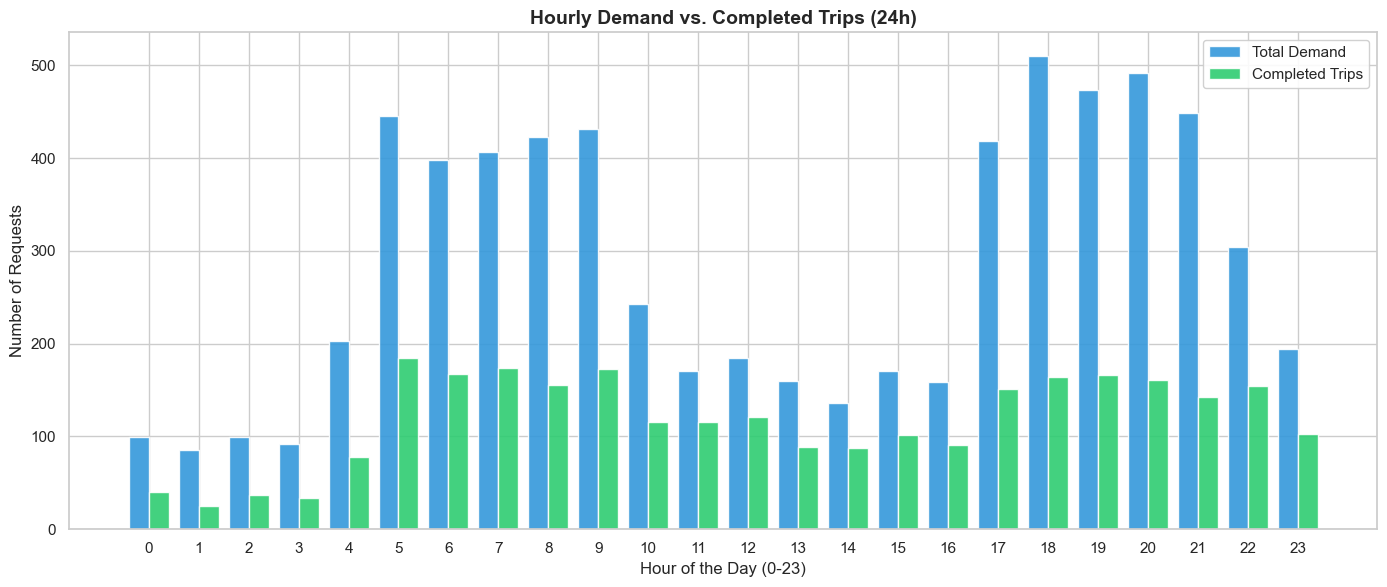

In [9]:
# Visualization 2: Total demand vs completed supply by hour
plt.figure(figsize=(14, 6))
bar_width = 0.4
x = hourly_df['request_hour']

plt.bar(x - bar_width/2, hourly_df['total_demand'], width=bar_width, label='Total Demand', color='#3498db', alpha=0.9)
plt.bar(x + bar_width/2, hourly_df['completed_supply'], width=bar_width, label='Completed Trips', color='#2ecc71', alpha=0.9)

plt.title("Hourly Demand vs. Completed Trips (24h)", fontsize=14, weight='bold')
plt.xlabel("Hour of the Day (0-23)", fontsize=12)
plt.ylabel("Number of Requests", fontsize=12)
plt.xticks(x)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()


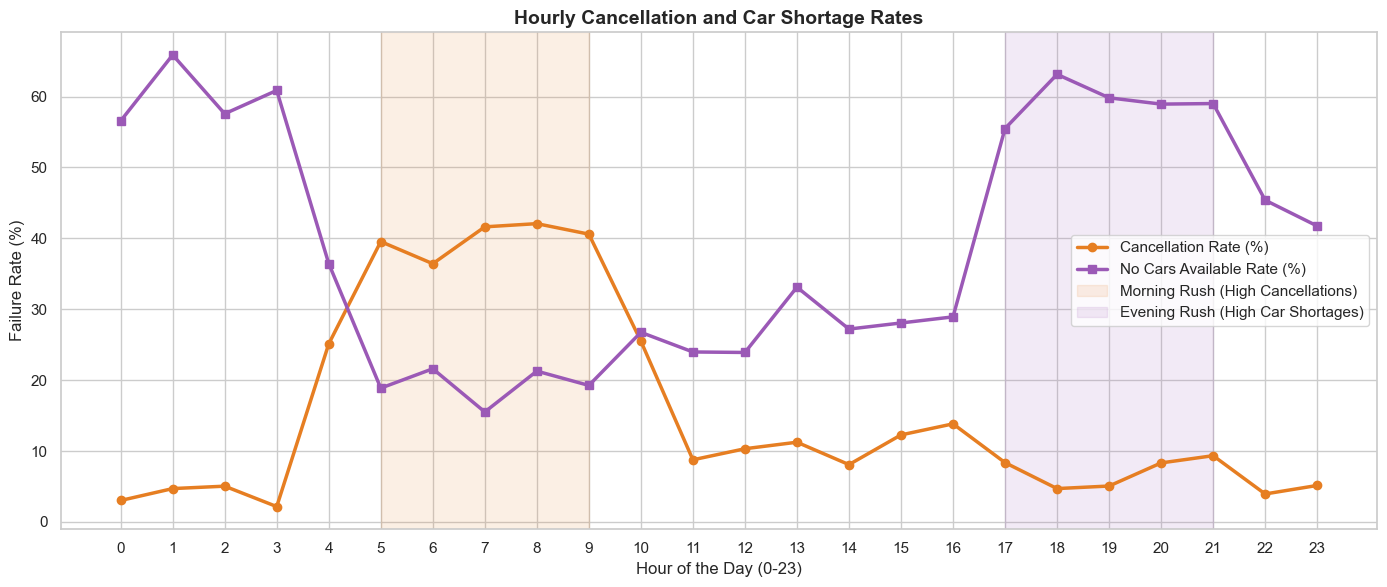

In [10]:
# Visualization 3: Hourly cancellation and car shortage rates
plt.figure(figsize=(14, 6))

plt.plot(hourly_df['request_hour'], hourly_df['cancellation_rate_pct'], 
         marker='o', linewidth=2.5, color='#e67e22', label='Cancellation Rate (%)')
plt.plot(hourly_df['request_hour'], hourly_df['no_cars_rate_pct'], 
         marker='s', linewidth=2.5, color='#9b59b6', label='No Cars Available Rate (%)')

plt.title("Hourly Cancellation and Car Shortage Rates", fontsize=14, weight='bold')
plt.xlabel("Hour of the Day (0-23)", fontsize=12)
plt.ylabel("Failure Rate (%)", fontsize=12)
plt.xticks(hourly_df['request_hour'])
plt.axvspan(5, 9, color='#e67e22', alpha=0.12, label='Morning Rush (High Cancellations)')
plt.axvspan(17, 21, color='#9b59b6', alpha=0.12, label='Evening Rush (High Car Shortages)')

plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()


### Note on Failure Percentage vs. Failure Volume

It is important to look at both the failure percentage and the actual number of failed trips:
- **Hour 1 (1:00 AM – 2:00 AM)** has a high failure rate of **70.59%**, but only **85 total requests** (60 unfulfilled).
- **Hour 18 (6:00 PM – 7:00 PM)** has a failure rate of **67.84%**, but represents **510 total requests** (**346 unfulfilled trips**).

Prioritizing by the total number of unfulfilled requests ensures that operational fixes target the hours where the most riders are impacted.


## 6. Pickup Location Analysis: City vs. Airport

Next, I compare ride outcomes between requests starting in the **City** and those starting at the **Airport**.


In [11]:
loc_summary = df.groupby('pickup_point').agg(
    total_requests=('request_id', 'count'),
    completed=('is_completed', 'sum'),
    cancelled=('is_cancelled', 'sum'),
    no_cars=('is_no_cars', 'sum'),
    unfulfilled=('is_unfulfilled', 'sum')
).reset_index()

loc_summary['completion_rate'] = (loc_summary['completed'] / loc_summary['total_requests'] * 100).round(2)
loc_summary['cancellation_rate'] = (loc_summary['cancelled'] / loc_summary['total_requests'] * 100).round(2)
loc_summary['no_cars_rate'] = (loc_summary['no_cars'] / loc_summary['total_requests'] * 100).round(2)
loc_summary['unfulfilled_rate'] = (loc_summary['unfulfilled'] / loc_summary['total_requests'] * 100).round(2)

print("=== PICKUP LOCATION COMPARISON ===")
print(loc_summary.to_string(index=False))


=== PICKUP LOCATION COMPARISON ===
pickup_point  total_requests  completed  cancelled  no_cars  unfulfilled  completion_rate  cancellation_rate  no_cars_rate  unfulfilled_rate
     Airport            3238       1327        198     1713         1911            40.98               6.11         52.90             59.02
        City            3507       1504       1066      937         2003            42.89              30.40         26.72             57.11


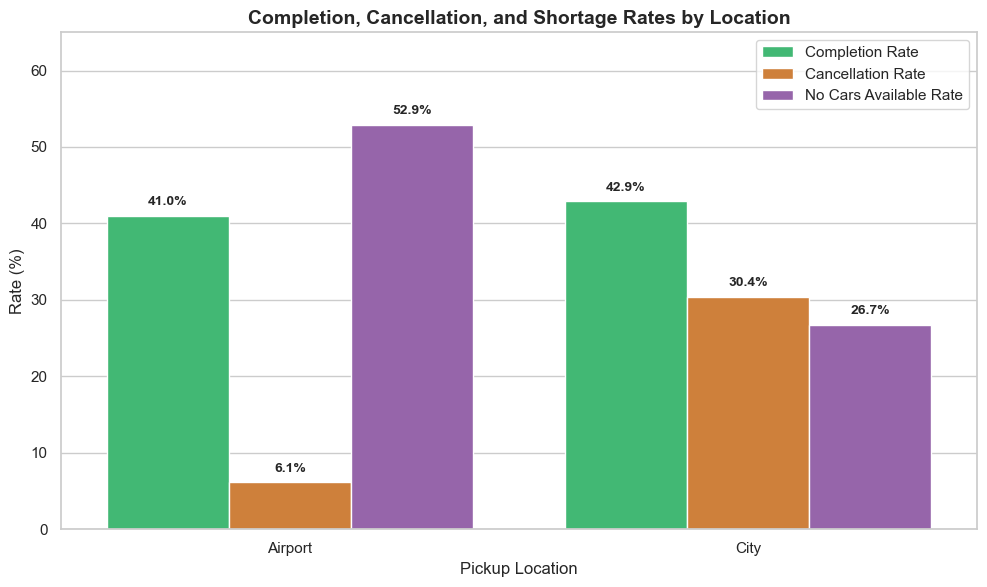

In [12]:
# Visualization 4: Rates by pickup location
fig, ax = plt.subplots(figsize=(10, 6))

loc_melted = pd.melt(
    loc_summary,
    id_vars=['pickup_point'],
    value_vars=['completion_rate', 'cancellation_rate', 'no_cars_rate'],
    var_name='Metric',
    value_name='Rate_Pct'
)
metric_labels = {
    'completion_rate': 'Completion Rate',
    'cancellation_rate': 'Cancellation Rate',
    'no_cars_rate': 'No Cars Available Rate'
}
loc_melted['Metric'] = loc_melted['Metric'].map(metric_labels)

sns.barplot(data=loc_melted, x='pickup_point', y='Rate_Pct', hue='Metric', 
            palette=['#2ecc71', '#e67e22', '#9b59b6'], ax=ax)

ax.set_title("Completion, Cancellation, and Shortage Rates by Location", fontsize=14, weight='bold')
ax.set_ylabel("Rate (%)", fontsize=12)
ax.set_xlabel("Pickup Location", fontsize=12)
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.1f}%", 
                    (p.get_x() + p.get_width() / 2., height + 1),
                    ha='center', va='bottom', fontsize=10, weight='bold')

ax.set_ylim(0, 65)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()


## 7. Rush Hour Breakdown by Location

When looking at pickup location and hour together, the patterns become very clear:
- The City had more cancellations during the morning.
- The Airport had more car shortages in the evening.


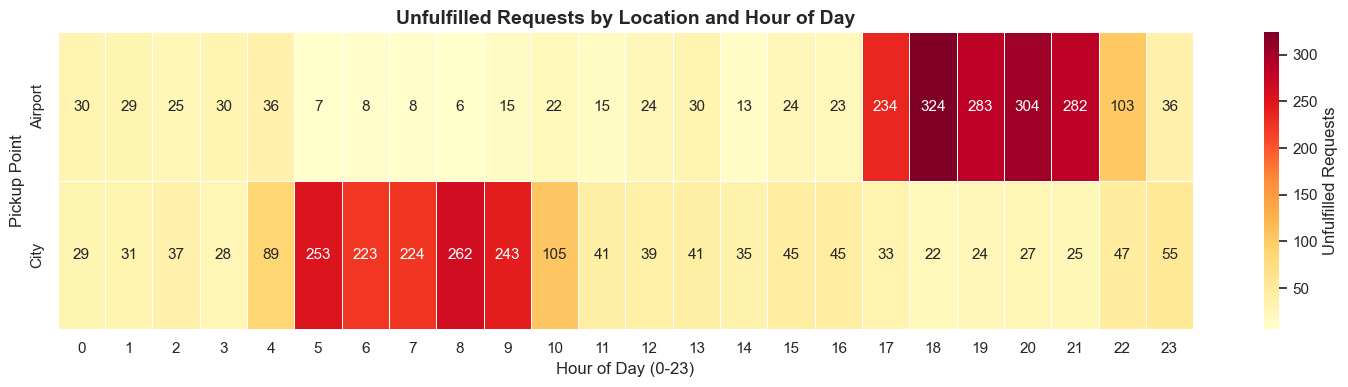

In [13]:
# Visualization 5: Heatmap of unfulfilled requests by location and hour
unfulfilled_matrix = df[df['is_unfulfilled'] == 1].pivot_table(
    index='pickup_point',
    columns='request_hour',
    values='request_id',
    aggfunc='count',
    fill_value=0
)

plt.figure(figsize=(15, 4))
sns.heatmap(unfulfilled_matrix, cmap='YlOrRd', annot=True, fmt='d', linewidths=0.5, cbar_kws={'label': 'Unfulfilled Requests'})
plt.title("Unfulfilled Requests by Location and Hour of Day", fontsize=14, weight='bold')
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Pickup Point", fontsize=12)
plt.tight_layout()
plt.show()


In [14]:
# Summary table of morning and evening rush periods
morning_rush = df[df['request_hour'].between(5, 9)]
evening_rush = df[df['request_hour'].between(17, 21)]

def summarize_window(sub_df, name):
    total = len(sub_df)
    completed = (sub_df['status'] == 'Trip Completed').sum()
    cancelled = (sub_df['status'] == 'Cancelled').sum()
    no_cars = (sub_df['status'] == 'No Cars Available').sum()
    unfulfilled = total - completed
    return {
        'Peak Window': name,
        'Total Demand': total,
        'Completed': completed,
        'Unfulfilled': unfulfilled,
        'Cancellations': cancelled,
        'No Cars': no_cars,
        'Unfulfilled Rate (%)': round(unfulfilled / total * 100, 2),
        'Cancellation Share (%)': round(cancelled / unfulfilled * 100, 2),
        'No-Car Share (%)': round(no_cars / unfulfilled * 100, 2)
    }

peak_comparison = pd.DataFrame([
    summarize_window(morning_rush, 'Morning Rush (Hours 5-9)'),
    summarize_window(evening_rush, 'Evening Rush (Hours 17-21)')
])

print("=== 1. OVERALL PEAK WINDOW COMPARISON ===")
print(peak_comparison.to_string(index=False))

# Location specific metrics with explicit formulas
m_city = morning_rush[morning_rush['pickup_point'] == 'City']
e_airport = evening_rush[evening_rush['pickup_point'] == 'Airport']

print("\n=== 2. DETAILED LOCATION RUSH METRICS & FORMULAS ===")
print(f"Morning City Total Requests (Hours 5-9): {len(m_city)}")
print(f"Morning City Cancellations: {(m_city['status'] == 'Cancelled').sum()}")
print(f"Morning City Cancellation Rate: {(m_city['status'] == 'Cancelled').sum()} / {len(m_city)} = {(m_city['status'] == 'Cancelled').sum() / len(m_city) * 100:.2f}%")
print(f"Morning City share of ALL dataset cancellations: {(m_city['status'] == 'Cancelled').sum()} / 1264 = {(m_city['status'] == 'Cancelled').sum() / 1264 * 100:.2f}%")

print(f"\nEvening Airport Total Requests (Hours 17-21): {len(e_airport)}")
print(f"Evening Airport No Cars Available: {(e_airport['status'] == 'No Cars Available').sum()}")
print(f"Evening Airport Car-Shortage Rate: {(e_airport['status'] == 'No Cars Available').sum()} / {len(e_airport)} = {(e_airport['status'] == 'No Cars Available').sum() / len(e_airport) * 100:.2f}%")
print(f"Evening Airport share of ALL dataset car shortages: {(e_airport['status'] == 'No Cars Available').sum()} / 2650 = {(e_airport['status'] == 'No Cars Available').sum() / 2650 * 100:.2f}%")


=== 1. OVERALL PEAK WINDOW COMPARISON ===
               Peak Window  Total Demand  Completed  Unfulfilled  Cancellations  No Cars  Unfulfilled Rate (%)  Cancellation Share (%)  No-Car Share (%)
  Morning Rush (Hours 5-9)          2103        854         1249            843      406                 59.39                   67.49             32.51
Evening Rush (Hours 17-21)          2342        784         1558            166     1392                 66.52                   10.65             89.35

=== 2. DETAILED LOCATION RUSH METRICS & FORMULAS ===
Morning City Total Requests (Hours 5-9): 1677
Morning City Cancellations: 820
Morning City Cancellation Rate: 820 / 1677 = 48.90%
Morning City share of ALL dataset cancellations: 820 / 1264 = 64.87%

Evening Airport Total Requests (Hours 17-21): 1800
Evening Airport No Cars Available: 1321
Evening Airport Car-Shortage Rate: 1321 / 1800 = 73.39%
Evening Airport share of ALL dataset car shortages: 1321 / 2650 = 49.85%


## 8. Key Findings

### Finding 1: Two Separate Problems Across the Day
- **Morning Rush (5:00 AM to 9:59 AM / Hours 5–9, City Pickups):**
  - **Demand:** 1,677 requests.
  - **Cancellations:** 820 cancelled trips.
  - **Cancellation Rate:** **48.90%** (`820 / 1,677`). Peak single hour reached **50.77%** at Hour 7 (`164 / 323`).
  - **Impact:** Accounts for **64.87%** of all 1,264 cancellations across the entire 5-day dataset (`820 / 1,264`).
  - *Hypothesis (Requires External Data):* The dataset does not track driver earnings or where drivers go after dropping off a rider. A common hypothesis is that city drivers avoid early morning airport trips because they expect few returning riders from the airport, which would mean driving back empty. Checking this would require flight schedules and driver location logs.

- **Evening Rush (5:00 PM to 9:59 PM / Hours 17–21, Airport Pickups):**
  - **Demand:** 1,800 requests.
  - **Car Shortages (`No Cars Available`):** 1,321 instances.
  - **Car-Shortage Rate:** **73.39%** (`1,321 / 1,800`). Peak single hour reached **76.30%** at Hour 18 (`309 / 405`).
  - **Impact:** Accounts for **49.85%** of all 2,650 vehicle shortages across the entire 5-day dataset (`1,321 / 2,650`).
  - *Hypothesis (Requires External Data):* The dataset does not track available cars waiting near the airport or flight arrival passenger volumes. The high number of shortages suggests that passenger demand outstrips available cars nearby in the evening. Checking whether this matches flight arrival peaks would require airport flight timetables and queue logs.

### Finding 2: 58.03% of All Requests Were Unfulfilled
Out of 6,745 total requests, only **2,831 trips were completed (41.97%)**. Over half went unfulfilled (`3,914 / 6,745 = 58.03%`):
- **67.71%** were due to no cars being available (`2,650 / 3,914`).
- **32.29%** were due to driver cancellations (`1,264 / 3,914`).

### Finding 3: Midday Runs More Smoothly
Midday hours (10 AM to 5 PM) have relatively better completion rates (~55–60%), showing that unfulfilled requests are heavily concentrated during the morning and evening rush periods.

---

### Ideas to Test (Hypotheses, Not Proven Results):
1. **Airport Scheduling:** Test sharing flight arrival schedules with drivers between 4:30 PM and 9:30 PM so more cars are near the airport before passenger demand peaks.
2. **Morning Airport Incentives:** Test giving drivers a return-trip guarantee or return subsidy for City-to-Airport trips between 5:00 AM and 9:00 AM to see if cancellations decrease.
3. **Separate Tracking:** Track ride completion separately for the Airport and the City, so citywide averages do not hide airport car shortages.
